In [ ]:
# Maven Toys — Business Performance Diagnosis

## Day 2: Exploratory Data Analysis and Root-Cause Investigation

### Business Problem
Why is Maven Toys' gross profit margin declining despite revenue growth?

### Objective
Identify the product, category, and store-level drivers of margin decline
and develop three data-driven recommendations for management.

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn

In [35]:
%pip install matplotlib seaborn "numpy==1.26.4"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Python312\python.exe -m pip install --upgrade pip


In [36]:
%pip install --user matplotlib seaborn "numpy==1.26.4"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Python312\python.exe -m pip install --upgrade pip


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [38]:
sales = pd.read_csv(
    r"C:\Users\Samiksha\Desktop\Business_performance_Dashboard\Data\processed data\maven_toys_cleaned.csv",
    parse_dates=['Date']
)

In [39]:
sales.shape

(829262, 16)

In [40]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 829262 entries, 0 to 829261
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   Sale_ID           829262 non-null  int64         
 1   Date              829262 non-null  datetime64[ns]
 2   Store_ID          829262 non-null  int64         
 3   Product_ID        829262 non-null  int64         
 4   Units             829262 non-null  int64         
 5   Product_Name      829262 non-null  object        
 6   Product_Category  829262 non-null  object        
 7   Product_Cost      829262 non-null  float64       
 8   Product_Price     829262 non-null  float64       
 9   Store_Name        829262 non-null  object        
 10  Store_City        829262 non-null  object        
 11  Store_Location    829262 non-null  object        
 12  Store_Open_Date   829262 non-null  object        
 13  Revenue           829262 non-null  float64       
 14  COGS

In [41]:
sales[['Date', 'Revenue', 'COGS', 'Gross_Profit']].isna().sum()

Date            0
Revenue         0
COGS            0
Gross_Profit    0
dtype: int64

In [42]:
print("Start:", sales['Date'].min())
print("End:", sales['Date'].max())

Start: 2022-01-01 00:00:00
End: 2023-09-30 00:00:00


In [43]:
# Keep January–September for both years.Filter correct comparison periods
sales_yoy = sales[
    (sales['Date'].dt.month <= 9) &
    (sales['Date'].dt.year.isin([2022, 2023]))
].copy()

# Extract the year
sales_yoy['Year'] = sales_yoy['Date'].dt.year

# Verify the result
print("Rows:", sales_yoy.shape[0])
print("Years:", sales_yoy['Year'].unique())

sales_yoy[['Date', 'Year', 'Product_Category']].head()

Rows: 705472
Years: [2022 2023]


,Date,Year,Product_Category
0,2022-01-01,2022,Games
1,2022-01-01,2022,Toys
2,2022-01-01,2022,Games
3,2022-01-01,2022,Sports & Outdoors
4,2022-01-01,2022,Toys


In [44]:
# calculate category revenue & gross profit
category_summary = (
    sales_yoy
    .groupby(['Year', 'Product_Category'])
    .agg(
        Revenue=('Revenue', 'sum'),
        Gross_Profit=('Gross_Profit', 'sum'),
        Units_Sold=('Units', 'sum')
    )
    .reset_index()
)

category_summary

,Year,Product_Category,Revenue,Gross_Profit,Units_Sold
0,2022,Art & Crafts,511146.27,144660.0,66873
1,2022,Electronics,1117477.73,537290.0,69727
2,2022,Games,829956.68,261807.0,75232
3,2022,Sports & Outdoors,841765.18,184973.0,67482
4,2022,Toys,2019769.99,443307.0,105101
5,2023,Art & Crafts,1798723.38,480405.0,203062
6,2023,Electronics,806312.06,327030.0,45594
7,2023,Games,998192.68,295612.0,86232
8,2023,Sports & Outdoors,1052931.70,250692.0,80330
9,2023,Toys,2305914.45,470503.0,125855


In [45]:
# calculate category gross margin
category_summary['Gross_Margin_Pct'] = (
    category_summary['Gross_Profit'] /
    category_summary['Revenue']
) * 100

category_summary.round(2)

,Year,Product_Category,Revenue,Gross_Profit,Units_Sold,Gross_Margin_Pct
0,2022,Art & Crafts,511146.27,144660.0,66873,28.30
1,2022,Electronics,1117477.73,537290.0,69727,48.08
2,2022,Games,829956.68,261807.0,75232,31.54
3,2022,Sports & Outdoors,841765.18,184973.0,67482,21.97
4,2022,Toys,2019769.99,443307.0,105101,21.95
5,2023,Art & Crafts,1798723.38,480405.0,203062,26.71
6,2023,Electronics,806312.06,327030.0,45594,40.56
7,2023,Games,998192.68,295612.0,86232,29.61
8,2023,Sports & Outdoors,1052931.70,250692.0,80330,23.81
9,2023,Toys,2305914.45,470503.0,125855,20.40


In [46]:
#calculate category revenue share
category_summary['Year_Total_Revenue'] = (
    category_summary
    .groupby('Year')['Revenue']
    .transform('sum')
)

category_summary['Revenue_Share_Pct'] = (
    category_summary['Revenue'] /
    category_summary['Year_Total_Revenue']
) * 100

category_summary.round(2)


,Year,Product_Category,Revenue,Gross_Profit,Units_Sold,Gross_Margin_Pct,Year_Total_Revenue,Revenue_Share_Pct
0,2022,Art & Crafts,511146.27,144660.0,66873,28.30,5320115.85,9.61
1,2022,Electronics,1117477.73,537290.0,69727,48.08,5320115.85,21.00
2,2022,Games,829956.68,261807.0,75232,31.54,5320115.85,15.60
3,2022,Sports & Outdoors,841765.18,184973.0,67482,21.97,5320115.85,15.82
4,2022,Toys,2019769.99,443307.0,105101,21.95,5320115.85,37.96
5,2023,Art & Crafts,1798723.38,480405.0,203062,26.71,6962074.27,25.84
6,2023,Electronics,806312.06,327030.0,45594,40.56,6962074.27,11.58
7,2023,Games,998192.68,295612.0,86232,29.61,6962074.27,14.34
8,2023,Sports & Outdoors,1052931.70,250692.0,80330,23.81,6962074.27,15.12
9,2023,Toys,2305914.45,470503.0,125855,20.40,6962074.27,33.12


In [47]:
category_comparison = category_summary.pivot(
    index='Product_Category',
    columns='Year',
    values=[
        'Revenue',
        'Gross_Profit',
        'Gross_Margin_Pct',
        'Revenue_Share_Pct'
    ]
)

category_comparison.columns = [
    f'{metric}_{year}'
    for metric, year in category_comparison.columns
]

category_comparison = category_comparison.reset_index()

category_comparison.round(2)

,Product_Category,Revenue_2022,Revenue_2023,Gross_Profit_2022,Gross_Profit_2023,Gross_Margin_Pct_2022,Gross_Margin_Pct_2023,Revenue_Share_Pct_2022,Revenue_Share_Pct_2023
0,Art & Crafts,511146.27,1798723.38,144660.0,480405.0,28.30,26.71,9.61,25.84
1,Electronics,1117477.73,806312.06,537290.0,327030.0,48.08,40.56,21.00,11.58
2,Games,829956.68,998192.68,261807.0,295612.0,31.54,29.61,15.60,14.34
3,Sports & Outdoors,841765.18,1052931.70,184973.0,250692.0,21.97,23.81,15.82,15.12
4,Toys,2019769.99,2305914.45,443307.0,470503.0,21.95,20.40,37.96,33.12


In [48]:
#Calculate the revenue-share change
category_comparison['Revenue_Share_Change_pp'] = (
    category_comparison['Revenue_Share_Pct_2023'] -
    category_comparison['Revenue_Share_Pct_2022']
)

category_comparison = category_comparison.sort_values(
    'Revenue_Share_Change_pp',
    ascending=False
)

category_comparison[
    [
        'Product_Category',
        'Gross_Margin_Pct_2022',
        'Gross_Margin_Pct_2023',
        'Revenue_Share_Pct_2022',
        'Revenue_Share_Pct_2023',
        'Revenue_Share_Change_pp'
    ]
].round(2)



,Product_Category,Gross_Margin_Pct_2022,Gross_Margin_Pct_2023,Revenue_Share_Pct_2022,Revenue_Share_Pct_2023,Revenue_Share_Change_pp
0,Art & Crafts,28.30,26.71,9.61,25.84,16.23
3,Sports & Outdoors,21.97,23.81,15.82,15.12,-0.70
2,Games,31.54,29.61,15.60,14.34,-1.26
4,Toys,21.95,20.40,37.96,33.12,-4.84
1,Electronics,48.08,40.56,21.00,11.58,-9.42


In [49]:
#validate the calculations
category_summary.groupby('Year')['Revenue_Share_Pct'].sum().round(2)

Year
2022    100.0
2023    100.0
Name: Revenue_Share_Pct, dtype: float64

In [50]:
category_comparison['Revenue_Share_Change_pp'].sum()

3.552713678800501e-15

In [ ]:
**Conclusion:** Between January–September 2022 and 2023, Art & Crafts gained the most revenue share, while Sports & Outdoors lost the most. Art & Crafts had a higher 2023 gross margin (26%) than Sports & Outdoors (23%). Therefore, this particular revenue-share shift does not appear to explain the company's declining gross margin. Further product-level analysis is needed to identify potential margin-diluting shifts.

In [20]:
sales_yoy = sales[
    (sales['Date'].dt.month <= 9) &
    (sales['Date'].dt.year.isin([2022, 2023]))
].copy()

sales_yoy['Year'] = sales_yoy['Date'].dt.year

In [21]:
#Calculate product-level revenue and profit
product_summary = (
    sales_yoy
    .groupby(
        ['Year', 'Product_ID', 'Product_Name', 'Product_Category']
    )
    .agg(
        Revenue=('Revenue', 'sum'),
        Gross_Profit=('Gross_Profit', 'sum'),
        Units_Sold=('Units', 'sum')
    )
    .reset_index()
)

In [22]:
product_summary

,Year,Product_ID,Product_Name,Product_Category,Revenue,Gross_Profit,Units_Sold
0,2022,1,Action Figure,Toys,471641.04,176976.0,29496
1,2022,2,Animal Figures,Toys,215672.97,49809.0,16603
2,2022,3,Barrel O' Slime,Art & Crafts,21270.69,10662.0,5331
3,2022,4,Chutes & Ladders,Games,13431.66,3102.0,1034
4,2022,5,Classic Dominoes,Games,19360.62,3876.0,1938
...,...,...,...,...,...,...,...
62,2023,31,Splash Balls,Sports & Outdoors,208639.92,23208.0,23208
63,2023,32,Supersoaker Water Gun,Sports & Outdoors,39168.87,7839.0,2613
64,2023,33,Teddy Bear,Toys,39164.85,6030.0,3015
65,2023,34,Toy Robot,Electronics,125947.54,24230.0,4846


In [25]:
# STEP 3 — Calculate product gross margin %
product_summary['Gross_Margin_Pct'] = (
    product_summary['Gross_Profit'] /
    product_summary['Revenue']
) * 100
product_summary.head(10).round(2)

,Year,Product_ID,Product_Name,Product_Category,Revenue,Gross_Profit,Units_Sold,Gross_Margin_Pct
0,2022,1,Action Figure,Toys,471641.04,176976.0,29496,37.52
1,2022,2,Animal Figures,Toys,215672.97,49809.0,16603,23.09
2,2022,3,Barrel O' Slime,Art & Crafts,21270.69,10662.0,5331,50.13
3,2022,4,Chutes & Ladders,Games,13431.66,3102.0,1034,23.09
4,2022,5,Classic Dominoes,Games,19360.62,3876.0,1938,20.02
5,2022,6,Colorbuds,Electronics,931433.63,497096.0,62137,53.37
6,2022,7,Dart Gun,Sports & Outdoors,257870.73,64508.0,16127,25.02
7,2022,8,Deck Of Cards,Games,244908.63,105111.0,35037,42.92
8,2022,9,Dino Egg,Toys,118615.07,10793.0,10793,9.10
9,2022,10,Dinosaur Figures,Toys,189188.79,50484.0,12621,26.68


In [27]:
# STEP 4 — Calculate product revenue share %
product_summary['Year_Total_Revenue'] = (
    product_summary
    .groupby('Year')['Revenue']
    .transform('sum')
)

product_summary['Revenue_Share_Pct'] = (
    product_summary['Revenue'] /
    product_summary['Year_Total_Revenue']
) * 100


In [28]:
# STEP 5 — Compare products between 2022 and 2023
product_comparison = product_summary.pivot_table(
    index=['Product_ID', 'Product_Name', 'Product_Category'],
    columns='Year',
    values=[
        'Revenue',
        'Gross_Profit',
        'Gross_Margin_Pct',
        'Revenue_Share_Pct'
    ],
    aggfunc='sum'
)

product_comparison.columns = [
    f'{metric}_{year}'
    for metric, year in product_comparison.columns
]

product_comparison = product_comparison.reset_index()


In [29]:
# STEP 6 — Calculate revenue-share change
product_comparison['Revenue_Share_Change_pp'] = (
    product_comparison['Revenue_Share_Pct_2023'] -
    product_comparison['Revenue_Share_Pct_2022']
)

product_comparison = product_comparison.sort_values(
    'Revenue_Share_Change_pp',
    ascending=False
)


In [30]:
# STEP 7 — Calculate overall company gross margin in 2023
company_margin_2023 = (
    sales_yoy.loc[
        sales_yoy['Year'] == 2023, 'Gross_Profit'
    ].sum()
    /
    sales_yoy.loc[
        sales_yoy['Year'] == 2023, 'Revenue'
    ].sum()
) * 100

print("Company Gross Margin 2023:",
      round(company_margin_2023, 2))


Company Gross Margin 2023: 26.2


In [31]:
# STEP 8 — Classify products by margin
import numpy as np

product_comparison['Margin_Class'] = np.where(
    product_comparison['Gross_Margin_Pct_2023'] < company_margin_2023,
    'Below Company Margin',
    'At or Above Company Margin'
)

In [32]:
# STEP 9 — Display complete comparison
display(
    product_comparison[
        [
            'Product_Name',
            'Product_Category',
            'Gross_Margin_Pct_2023',
            'Revenue_Share_Pct_2022',
            'Revenue_Share_Pct_2023',
            'Revenue_Share_Change_pp',
            'Margin_Class'
        ]
    ].round(2)
)

,Product_Name,Product_Category,Gross_Margin_Pct_2023,Revenue_Share_Pct_2022,Revenue_Share_Pct_2023,Revenue_Share_Change_pp,Margin_Class
18,Magic Sand,Art & Crafts,12.51,0.07,12.48,12.41,Below Company Margin
2,Barrel O' Slime,Art & Crafts,50.13,0.40,3.51,3.11,At or Above Company Margin
12,Gamer Headphones,Electronics,28.59,0.89,3.49,2.61,At or Above Company Margin
23,Nerf Gun,Sports & Outdoors,25.01,2.47,4.89,2.41,Below Company Margin
8,Dino Egg,Toys,9.10,2.23,4.28,2.05,Below Company Margin
20,Mini Ping Pong Set,Sports & Outdoors,30.03,1.56,2.68,1.12,At or Above Company Margin
22,Mr. Potatohead,Toys,50.05,0.02,0.92,0.90,At or Above Company Margin
24,PlayDoh Can,Art & Crafts,33.44,1.84,2.36,0.52,At or Above Company Margin
29,Rubik's Cube,Games,10.01,5.90,6.04,0.14,Below Company Margin
3,Chutes & Ladders,Games,23.09,0.25,0.35,0.10,Below Company Margin


In [33]:
# STEP 10 — Top 10 products gaining revenue share
print("TOP 10 PRODUCTS GAINING REVENUE SHARE")

display(
    product_comparison.nlargest(
        10, 'Revenue_Share_Change_pp'
    )[
        [
            'Product_Name',
            'Product_Category',
            'Gross_Margin_Pct_2023',
            'Revenue_Share_Change_pp',
            'Margin_Class'
        ]
    ].round(2)
)



TOP 10 PRODUCTS GAINING REVENUE SHARE


,Product_Name,Product_Category,Gross_Margin_Pct_2023,Revenue_Share_Change_pp,Margin_Class
18,Magic Sand,Art & Crafts,12.51,12.41,Below Company Margin
2,Barrel O' Slime,Art & Crafts,50.13,3.11,At or Above Company Margin
12,Gamer Headphones,Electronics,28.59,2.61,At or Above Company Margin
23,Nerf Gun,Sports & Outdoors,25.01,2.41,Below Company Margin
8,Dino Egg,Toys,9.10,2.05,Below Company Margin
20,Mini Ping Pong Set,Sports & Outdoors,30.03,1.12,At or Above Company Margin
22,Mr. Potatohead,Toys,50.05,0.90,At or Above Company Margin
24,PlayDoh Can,Art & Crafts,33.44,0.52,At or Above Company Margin
29,Rubik's Cube,Games,10.01,0.14,Below Company Margin
3,Chutes & Ladders,Games,23.09,0.10,Below Company Margin


In [34]:
# STEP 11 — Top 10 products losing revenue share
print("TOP 10 PRODUCTS LOSING REVENUE SHARE")

display(
    product_comparison.nsmallest(
        10, 'Revenue_Share_Change_pp'
    )[
        [
            'Product_Name',
            'Product_Category',
            'Gross_Margin_Pct_2023',
            'Revenue_Share_Change_pp',
            'Margin_Class'
        ]
    ].round(2)
)



TOP 10 PRODUCTS LOSING REVENUE SHARE


,Product_Name,Product_Category,Gross_Margin_Pct_2023,Revenue_Share_Change_pp,Margin_Class
5,Colorbuds,Electronics,53.37,-11.23,At or Above Company Margin
0,Action Figure,Toys,37.52,-4.06,At or Above Company Margin
6,Dart Gun,Sports & Outdoors,25.02,-2.49,Below Company Margin
16,Kids Makeup Kit,Art & Crafts,30.02,-2.41,At or Above Company Margin
30,Splash Balls,Sports & Outdoors,11.12,-2.35,Below Company Margin
17,Lego Bricks,Toys,12.50,-1.82,Below Company Margin
9,Dinosaur Figures,Toys,26.68,-0.97,At or Above Company Margin
7,Deck Of Cards,Games,42.92,-0.94,At or Above Company Margin
1,Animal Figures,Toys,23.09,-0.92,Below Company Margin
33,Toy Robot,Electronics,19.24,-0.80,Below Company Margin


In [35]:

# STEP 12 — Validate revenue shares
print("Revenue share totals:")
print(
    product_summary
    .groupby('Year')['Revenue_Share_Pct']
    .sum()
    .round(2)
)

print(
    "Total Revenue Share Change (pp):",
    round(
        product_comparison['Revenue_Share_Change_pp'].sum(),
        8
    )
)

Revenue share totals:
Year
2022    100.0
2023    100.0
Name: Revenue_Share_Pct, dtype: float64
Total Revenue Share Change (pp): -4.87111939


In [17]:
# calculate revenue and gross profit for every store
# STEP 3A — Store-level summary

store_summary = (
    sales_yoy
    .groupby([
        'Year',
        'Store_ID',
        'Store_Name',
        'Store_City',
        'Store_Location'
    ])
    .agg(
        Revenue=('Revenue', 'sum'),
        Gross_Profit=('Gross_Profit', 'sum'),
        Units_Sold=('Units', 'sum')
    )
    .reset_index()
)

display(store_summary.head(10).round(2))

,Year,Store_ID,Store_Name,Store_City,Store_Location,Revenue,Gross_Profit,Units_Sold
0,2022,1,Maven Toys Guadalajara 1,Guadalajara,Residential,88045.45,23193.0,6455
1,2022,2,Maven Toys Monterrey 1,Monterrey,Residential,127387.42,34085.0,8558
2,2022,3,Maven Toys Guadalajara 2,Guadalajara,Commercial,105563.38,33987.0,7962
3,2022,4,Maven Toys Saltillo 1,Saltillo,Downtown,124343.73,38081.0,8827
4,2022,5,Maven Toys La Paz 1,La Paz,Downtown,73417.20,21317.0,5180
5,2022,6,Maven Toys Mexicali 1,Mexicali,Commercial,111484.57,42071.0,8743
6,2022,7,Maven Toys Monterrey 2,Monterrey,Downtown,128703.86,41118.0,9314
7,2022,8,Maven Toys Pachuca 1,Pachuca,Downtown,84225.31,23450.0,6169
8,2022,9,Maven Toys Ciudad de Mexico 1,Cuidad de Mexico,Downtown,169297.77,43970.0,12123
9,2022,10,Maven Toys Campeche 1,Campeche,Downtown,110662.83,35256.0,8617


In [18]:
# Calculate store gross margin %
store_summary['Gross_Margin_Pct'] = (
    store_summary['Gross_Profit'] /
    store_summary['Revenue']
) * 100

display(
    store_summary[
        ['Year', 'Store_Name', 'Revenue',
         'Gross_Profit', 'Gross_Margin_Pct']
    ].head(10).round(2)
)

,Year,Store_Name,Revenue,Gross_Profit,Gross_Margin_Pct
0,2022,Maven Toys Guadalajara 1,88045.45,23193.0,26.34
1,2022,Maven Toys Monterrey 1,127387.42,34085.0,26.76
2,2022,Maven Toys Guadalajara 2,105563.38,33987.0,32.20
3,2022,Maven Toys Saltillo 1,124343.73,38081.0,30.63
4,2022,Maven Toys La Paz 1,73417.20,21317.0,29.04
5,2022,Maven Toys Mexicali 1,111484.57,42071.0,37.74
6,2022,Maven Toys Monterrey 2,128703.86,41118.0,31.95
7,2022,Maven Toys Pachuca 1,84225.31,23450.0,27.84
8,2022,Maven Toys Ciudad de Mexico 1,169297.77,43970.0,25.97
9,2022,Maven Toys Campeche 1,110662.83,35256.0,31.86


In [19]:
# Calculate store revenue share %
store_summary['Company_Revenue'] = (
    store_summary
    .groupby('Year')['Revenue']
    .transform('sum')
)

store_summary['Revenue_Share_Pct'] = (
    store_summary['Revenue'] /
    store_summary['Company_Revenue']
) * 100

display(
    store_summary[
        ['Year', 'Store_Name', 'Revenue',
         'Company_Revenue', 'Revenue_Share_Pct']
    ].head(10).round(2)
)

,Year,Store_Name,Revenue,Company_Revenue,Revenue_Share_Pct
0,2022,Maven Toys Guadalajara 1,88045.45,5320115.85,1.65
1,2022,Maven Toys Monterrey 1,127387.42,5320115.85,2.39
2,2022,Maven Toys Guadalajara 2,105563.38,5320115.85,1.98
3,2022,Maven Toys Saltillo 1,124343.73,5320115.85,2.34
4,2022,Maven Toys La Paz 1,73417.20,5320115.85,1.38
5,2022,Maven Toys Mexicali 1,111484.57,5320115.85,2.10
6,2022,Maven Toys Monterrey 2,128703.86,5320115.85,2.42
7,2022,Maven Toys Pachuca 1,84225.31,5320115.85,1.58
8,2022,Maven Toys Ciudad de Mexico 1,169297.77,5320115.85,3.18
9,2022,Maven Toys Campeche 1,110662.83,5320115.85,2.08


In [20]:
# Compare store performance between 2022 and 2023

store_comparison = store_summary.pivot_table(
    index=[
        'Store_ID',
        'Store_Name',
        'Store_City',
        'Store_Location'
    ],
    columns='Year',
    values=[
        'Revenue',
        'Gross_Profit',
        'Gross_Margin_Pct',
        'Revenue_Share_Pct'
    ],
    aggfunc='sum'
)

store_comparison.columns = [
    f'{metric}_{year}'
    for metric, year in store_comparison.columns
]

store_comparison = store_comparison.reset_index()

display(store_comparison.head(10).round(2))

,Store_ID,Store_Name,Store_City,Store_Location,Gross_Margin_Pct_2022,Gross_Margin_Pct_2023,Gross_Profit_2022,Gross_Profit_2023,Revenue_2022,Revenue_2023,Revenue_Share_Pct_2022,Revenue_Share_Pct_2023
0,1,Maven Toys Guadalajara 1,Guadalajara,Residential,26.34,26.75,23193.0,36064.0,88045.45,134821.66,1.65,1.94
1,2,Maven Toys Monterrey 1,Monterrey,Residential,26.76,26.25,34085.0,27897.0,127387.42,106270.72,2.39,1.53
2,3,Maven Toys Guadalajara 2,Guadalajara,Commercial,32.20,26.87,33987.0,31868.0,105563.38,118603.05,1.98,1.70
3,4,Maven Toys Saltillo 1,Saltillo,Downtown,30.63,27.01,38081.0,42558.0,124343.73,157561.48,2.34,2.26
4,5,Maven Toys La Paz 1,La Paz,Downtown,29.04,25.64,21317.0,26805.0,73417.20,104559.11,1.38,1.50
5,6,Maven Toys Mexicali 1,Mexicali,Commercial,37.74,28.81,42071.0,37569.0,111484.57,130399.70,2.10,1.87
6,7,Maven Toys Monterrey 2,Monterrey,Downtown,31.95,26.05,41118.0,49714.0,128703.86,190814.86,2.42,2.74
7,8,Maven Toys Pachuca 1,Pachuca,Downtown,27.84,26.14,23450.0,31915.0,84225.31,122107.29,1.58,1.75
8,9,Maven Toys Ciudad de Mexico 1,Cuidad de Mexico,Downtown,25.97,24.66,43970.0,50441.0,169297.77,204539.20,3.18,2.94
9,10,Maven Toys Campeche 1,Campeche,Downtown,31.86,25.59,35256.0,37077.0,110662.83,144895.01,2.08,2.08


In [21]:
# Calculate store revenue-share change

# Missing revenue shares mean no recorded sales in that year
for col in ['Revenue_Share_Pct_2022', 'Revenue_Share_Pct_2023']:
    store_comparison[col] = store_comparison[col].fillna(0)

store_comparison['Revenue_Share_Change_pp'] = (
    store_comparison['Revenue_Share_Pct_2023'] -
    store_comparison['Revenue_Share_Pct_2022']
)

store_comparison = store_comparison.sort_values(
    'Revenue_Share_Change_pp',
    ascending=False
)

display(
    store_comparison[
        [
            'Store_Name',
            'Store_City',
            'Gross_Margin_Pct_2022',
            'Gross_Margin_Pct_2023',
            'Revenue_Share_Pct_2022',
            'Revenue_Share_Pct_2023',
            'Revenue_Share_Change_pp'
        ]
    ].round(2)
)

,Store_Name,Store_City,Gross_Margin_Pct_2022,Gross_Margin_Pct_2023,Revenue_Share_Pct_2022,Revenue_Share_Pct_2023,Revenue_Share_Change_pp
48,Maven Toys Culiacan 1,Culiacan,26.37,25.19,1.37,2.12,0.76
32,Maven Toys Monterrey 3,Monterrey,32.03,29.14,1.70,2.35,0.65
18,Maven Toys Puebla 1,Puebla,32.25,27.42,1.37,2.00,0.62
16,Maven Toys Toluca 1,Toluca,26.74,24.16,2.64,2.99,0.34
36,Maven Toys Ciudad de Mexico 3,Cuidad de Mexico,27.79,27.51,2.19,2.54,0.34
19,Maven Toys Zacatecas 1,Zacatecas,27.08,24.70,1.38,1.72,0.34
24,Maven Toys Ciudad Victoria 1,Ciudad Victoria,34.13,24.81,1.86,2.18,0.33
6,Maven Toys Monterrey 2,Monterrey,31.95,26.05,2.42,2.74,0.32
26,Maven Toys Oaxaca 1,Oaxaca,25.47,23.80,1.44,1.73,0.29
0,Maven Toys Guadalajara 1,Guadalajara,26.34,26.75,1.65,1.94,0.28


In [22]:
# Identify the top 10 gaining and losing stores

print("TOP 10 STORES GAINING REVENUE SHARE")

display(
    store_comparison.nlargest(
        10, 'Revenue_Share_Change_pp'
    )[
        [
            'Store_Name',
            'Store_City',
            'Gross_Margin_Pct_2023',
            'Revenue_Share_Change_pp'
        ]
    ].round(2)
)


# Top 10 store revenue-share losers

print("TOP 10 STORES LOSING REVENUE SHARE")

display(
    store_comparison.nsmallest(
        10, 'Revenue_Share_Change_pp'
    )[
        [
            'Store_Name',
            'Store_City',
            'Gross_Margin_Pct_2023',
            'Revenue_Share_Change_pp'
        ]
    ].round(2)
)

TOP 10 STORES GAINING REVENUE SHARE


,Store_Name,Store_City,Gross_Margin_Pct_2023,Revenue_Share_Change_pp
48,Maven Toys Culiacan 1,Culiacan,25.19,0.76
32,Maven Toys Monterrey 3,Monterrey,29.14,0.65
18,Maven Toys Puebla 1,Puebla,27.42,0.62
16,Maven Toys Toluca 1,Toluca,24.16,0.34
36,Maven Toys Ciudad de Mexico 3,Cuidad de Mexico,27.51,0.34
19,Maven Toys Zacatecas 1,Zacatecas,24.70,0.34
24,Maven Toys Ciudad Victoria 1,Ciudad Victoria,24.81,0.33
6,Maven Toys Monterrey 2,Monterrey,26.05,0.32
26,Maven Toys Oaxaca 1,Oaxaca,23.80,0.29
0,Maven Toys Guadalajara 1,Guadalajara,26.75,0.28


TOP 10 STORES LOSING REVENUE SHARE


,Store_Name,Store_City,Gross_Margin_Pct_2023,Revenue_Share_Change_pp
1,Maven Toys Monterrey 1,Monterrey,26.25,-0.87
45,Maven Toys Guadalajara 4,Guadalajara,29.34,-0.77
23,Maven Toys Aguascalientes 1,Aguascalientes,28.28,-0.49
44,Maven Toys Ciudad de Mexico 4,Cuidad de Mexico,26.77,-0.46
47,Maven Toys Saltillo 2,Saltillo,28.00,-0.38
43,Maven Toys Puebla 3,Puebla,29.04,-0.37
2,Maven Toys Guadalajara 2,Guadalajara,26.87,-0.28
8,Maven Toys Ciudad de Mexico 1,Cuidad de Mexico,24.66,-0.24
30,Maven Toys Ciudad de Mexico 2,Cuidad de Mexico,27.91,-0.23
5,Maven Toys Mexicali 1,Mexicali,28.81,-0.22


In [23]:
# STEP 3G — Compare with company margin

import numpy as np

company_margin_2023 = (
    sales_yoy.loc[
        sales_yoy['Year'] == 2023, 'Gross_Profit'
    ].sum()
    /
    sales_yoy.loc[
        sales_yoy['Year'] == 2023, 'Revenue'
    ].sum()
) * 100

store_comparison['Margin_Class'] = np.where(
    store_comparison['Gross_Margin_Pct_2023'].isna(),
    'No 2023 Sales',
    np.where(
        store_comparison['Gross_Margin_Pct_2023'] < company_margin_2023,
        'Below Company Margin',
        'At or Above Company Margin'
    )
)

print("Company Gross Margin 2023:",
      round(company_margin_2023, 2), "%")

display(
    store_comparison[
        [
            'Store_Name',
            'Gross_Margin_Pct_2023',
            'Revenue_Share_Change_pp',
            'Margin_Class'
        ]
    ].round(2)
)

Company Gross Margin 2023: 26.2 %


,Store_Name,Gross_Margin_Pct_2023,Revenue_Share_Change_pp,Margin_Class
48,Maven Toys Culiacan 1,25.19,0.76,Below Company Margin
32,Maven Toys Monterrey 3,29.14,0.65,At or Above Company Margin
18,Maven Toys Puebla 1,27.42,0.62,At or Above Company Margin
16,Maven Toys Toluca 1,24.16,0.34,Below Company Margin
36,Maven Toys Ciudad de Mexico 3,27.51,0.34,At or Above Company Margin
19,Maven Toys Zacatecas 1,24.70,0.34,Below Company Margin
24,Maven Toys Ciudad Victoria 1,24.81,0.33,Below Company Margin
6,Maven Toys Monterrey 2,26.05,0.32,Below Company Margin
26,Maven Toys Oaxaca 1,23.80,0.29,Below Company Margin
0,Maven Toys Guadalajara 1,26.75,0.28,At or Above Company Margin


In [24]:
#Validation.Revenue share should add up to 100% for each year

print("Revenue Share Totals:")

display(
    store_summary
    .groupby('Year')['Revenue_Share_Pct']
    .sum()
    .round(2)
)

print("Total Revenue Share Change (pp):")

print(
    round(
        store_comparison['Revenue_Share_Change_pp'].sum(),
        8
    )
)

Revenue Share Totals:


Year
2022    100.0
2023    100.0
Name: Revenue_Share_Pct, dtype: float64

Total Revenue Share Change (pp):
-0.0


In [25]:
# ==========================================
# ANALYSIS 4A — COMPANY MARGIN CHANGE
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

company_summary = (
    sales_yoy
    .groupby('Year')
    .agg(
        Revenue=('Revenue', 'sum'),
        Gross_Profit=('Gross_Profit', 'sum'),
        Units_Sold=('Units', 'sum')
    )
)

company_summary['Gross_Margin_Pct'] = (
    company_summary['Gross_Profit'] /
    company_summary['Revenue']
) * 100

display(company_summary.round(2))

margin_2022 = company_summary.loc[2022, 'Gross_Margin_Pct']
margin_2023 = company_summary.loc[2023, 'Gross_Margin_Pct']

margin_change_pp = margin_2023 - margin_2022

print("2022 Gross Margin:", round(margin_2022, 2), "%")
print("2023 Gross Margin:", round(margin_2023, 2), "%")
print("Margin Change:", round(margin_change_pp, 2), "pp")

,Revenue,Gross_Profit,Units_Sold,Gross_Margin_Pct
Year,,,,
2022,5320115.85,1572037.0,384415,29.55
2023,6962074.27,1824242.0,541073,26.20


2022 Gross Margin: 29.55 %
2023 Gross Margin: 26.2 %
Margin Change: -3.35 pp


In [26]:
# ==========================================
# ANALYSIS 4B — PRODUCT MARGIN CONTRIBUTION
# ==========================================

# 1. Calculate product revenue and gross profit by year

product_mix = (
    sales_yoy
    .groupby([
        'Product_ID',
        'Product_Name',
        'Product_Category',
        'Year'
    ])
    .agg(
        Revenue=('Revenue', 'sum'),
        Gross_Profit=('Gross_Profit', 'sum')
    )
    .reset_index()
)


# 2. Rearrange 2022 and 2023 values side by side

product_mix = product_mix.pivot_table(
    index=[
        'Product_ID',
        'Product_Name',
        'Product_Category'
    ],
    columns='Year',
    values=['Revenue', 'Gross_Profit'],
    aggfunc='sum',
    fill_value=0
)

product_mix.columns = [
    f'{metric}_{year}'
    for metric, year in product_mix.columns
]

product_mix = product_mix.reset_index()


# 3. Calculate revenue share for both years

total_revenue_2022 = company_summary.loc[2022, 'Revenue']
total_revenue_2023 = company_summary.loc[2023, 'Revenue']

product_mix['Share_2022'] = (
    product_mix['Revenue_2022'] /
    total_revenue_2022
)

product_mix['Share_2023'] = (
    product_mix['Revenue_2023'] /
    total_revenue_2023
)


# 4. Calculate change in revenue share

product_mix['Share_Change'] = (
    product_mix['Share_2023'] -
    product_mix['Share_2022']
)


# 5. Calculate each product's gross margin
# Use combined-period totals because the product
# master contains fixed product prices and costs.

product_mix['Product_Margin'] = (
    (
        product_mix['Gross_Profit_2022'] +
        product_mix['Gross_Profit_2023']
    )
    /
    (
        product_mix['Revenue_2022'] +
        product_mix['Revenue_2023']
    )
)


# 6. Validate that margins are stable for products
# that had sales in both years

sold_both_years = (
    (product_mix['Revenue_2022'] > 0) &
    (product_mix['Revenue_2023'] > 0)
)

margin_diff = (
    product_mix.loc[sold_both_years, 'Gross_Profit_2022'] /
    product_mix.loc[sold_both_years, 'Revenue_2022']
    -
    product_mix.loc[sold_both_years, 'Gross_Profit_2023'] /
    product_mix.loc[sold_both_years, 'Revenue_2023']
).abs()

stable_product_margins = (
    margin_diff.lt(0.000001).all()
)

print("Product margins stable:", stable_product_margins)

if not stable_product_margins:
    raise ValueError(
        "Product margins changed. The fixed-margin "
        "mix decomposition needs adjustment."
    )


# 7. Calculate product contribution in percentage points

product_mix['Margin_Contribution_pp'] = (
    product_mix['Share_Change'] *
    (product_mix['Product_Margin'] - margin_2022 / 100)
) * 100


# 8. Display the products with the largest
# negative contributions first

product_mix = product_mix.sort_values(
    'Margin_Contribution_pp',
    ascending=True
)

display(
    product_mix[
        [
            'Product_Name',
            'Product_Category',
            'Product_Margin',
            'Share_Change',
            'Margin_Contribution_pp'
        ]
    ].assign(
        Product_Margin=lambda df: df['Product_Margin'] * 100,
        Share_Change=lambda df: df['Share_Change'] * 100
    ).round(3)
)

Product margins stable: True


,Product_Name,Product_Category,Product_Margin,Share_Change,Margin_Contribution_pp
5,Colorbuds,Electronics,53.369,-11.230,-2.675
18,Magic Sand,Art & Crafts,12.508,12.414,-2.116
8,Dino Egg,Toys,9.099,2.050,-0.419
0,Action Figure,Toys,37.523,-4.060,-0.324
7,Deck Of Cards,Games,42.918,-0.940,-0.126
23,Nerf Gun,Sports & Outdoors,25.013,2.415,-0.110
15,Jenga,Games,70.070,-0.259,-0.105
19,Mini Basketball Hoop,Sports & Outdoors,64.026,-0.271,-0.093
11,Foam Disk Launcher,Sports & Outdoors,25.021,1.312,-0.059
13,Glass Marbles,Games,45.496,-0.370,-0.059


In [27]:
# STEP 4B — VALIDATION

total_product_contribution = (
    product_mix['Margin_Contribution_pp'].sum()
)

print(
    "Actual Margin Change:",
    round(margin_change_pp, 4), "pp"
)

print(
    "Total Product Mix Contribution:",
    round(total_product_contribution, 4), "pp"
)

print(
    "Difference:",
    round(
        margin_change_pp - total_product_contribution,
        8
    ), "pp"
)

assert np.isclose(
    margin_change_pp,
    total_product_contribution,
    atol=0.000001
), "Product contributions do not reconcile."

Actual Margin Change: -3.3464 pp
Total Product Mix Contribution: -3.3464 pp
Difference: 0.0 pp


In [28]:
# ==========================================
# ANALYSIS 4C — CATEGORY VS WITHIN-CATEGORY MIX
# ==========================================

# 1. Calculate category revenue and profit by year

category_mix = (
    sales_yoy
    .groupby(['Product_Category', 'Year'])
    .agg(
        Revenue=('Revenue', 'sum'),
        Gross_Profit=('Gross_Profit', 'sum')
    )
    .reset_index()
)


# 2. Compare 2022 and 2023

category_mix = category_mix.pivot_table(
    index='Product_Category',
    columns='Year',
    values=['Revenue', 'Gross_Profit'],
    aggfunc='sum',
    fill_value=0
)

category_mix.columns = [
    f'{metric}_{year}'
    for metric, year in category_mix.columns
]

category_mix = category_mix.reset_index()


# 3. Calculate category share in company revenue

category_mix['Share_2022'] = (
    category_mix['Revenue_2022'] /
    total_revenue_2022
)

category_mix['Share_2023'] = (
    category_mix['Revenue_2023'] /
    total_revenue_2023
)


# 4. Calculate category margins
# Both periods must have sales for each category

if (
    (category_mix['Revenue_2022'] <= 0) |
    (category_mix['Revenue_2023'] <= 0)
).any():
    raise ValueError(
        "Some categories lack sales in one year. "
        "Their base margins require separate handling."
    )

category_mix['Margin_2022'] = (
    category_mix['Gross_Profit_2022'] /
    category_mix['Revenue_2022']
)

category_mix['Margin_2023'] = (
    category_mix['Gross_Profit_2023'] /
    category_mix['Revenue_2023']
)


# 5. Category-mix effect
# Measures category share shifts at 2022 margins

category_mix['Category_Mix_Effect_pp'] = (
    (
        category_mix['Share_2023'] -
        category_mix['Share_2022']
    )
    *
    (
        category_mix['Margin_2022'] -
        margin_2022 / 100
    )
) * 100


# 6. Within-category product-mix effect
# Measures category margin changes weighted by
# each category's 2023 revenue share

category_mix['Within_Category_Effect_pp'] = (
    category_mix['Share_2023'] *
    (
        category_mix['Margin_2023'] -
        category_mix['Margin_2022']
    )
) * 100


# 7. Total contribution of each category

category_mix['Total_Effect_pp'] = (
    category_mix['Category_Mix_Effect_pp'] +
    category_mix['Within_Category_Effect_pp']
)


# 8. Display results

display(
    category_mix[
        [
            'Product_Category',
            'Category_Mix_Effect_pp',
            'Within_Category_Effect_pp',
            'Total_Effect_pp'
        ]
    ].sort_values(
        'Total_Effect_pp'
    ).round(4)
)

,Product_Category,Category_Mix_Effect_pp,Within_Category_Effect_pp,Total_Effect_pp
1,Electronics,-1.7463,-0.8711,-2.6174
0,Art & Crafts,-0.2025,-0.4116,-0.6141
2,Games,-0.0252,-0.2767,-0.3019
4,Toys,0.3681,-0.5115,-0.1433
3,Sports & Outdoors,0.0529,0.2775,0.3304


In [29]:
# STEP 4C — DECOMPOSITION SUMMARY

category_mix_total = (
    category_mix['Category_Mix_Effect_pp'].sum()
)

within_category_total = (
    category_mix['Within_Category_Effect_pp'].sum()
)

explained_change = (
    category_mix_total + within_category_total
)

print(
    "Category Mix Effect:",
    round(category_mix_total, 4), "pp"
)

print(
    "Within-Category Product Mix Effect:",
    round(within_category_total, 4), "pp"
)

print(
    "Total Explained Change:",
    round(explained_change, 4), "pp"
)

print(
    "Actual Gross Margin Change:",
    round(margin_change_pp, 4), "pp"
)

assert np.isclose(
    explained_change,
    margin_change_pp,
    atol=0.000001
), "Category decomposition does not reconcile."

Category Mix Effect: -1.5529 pp
Within-Category Product Mix Effect: -1.7934 pp
Total Explained Change: -3.3464 pp
Actual Gross Margin Change: -3.3464 pp


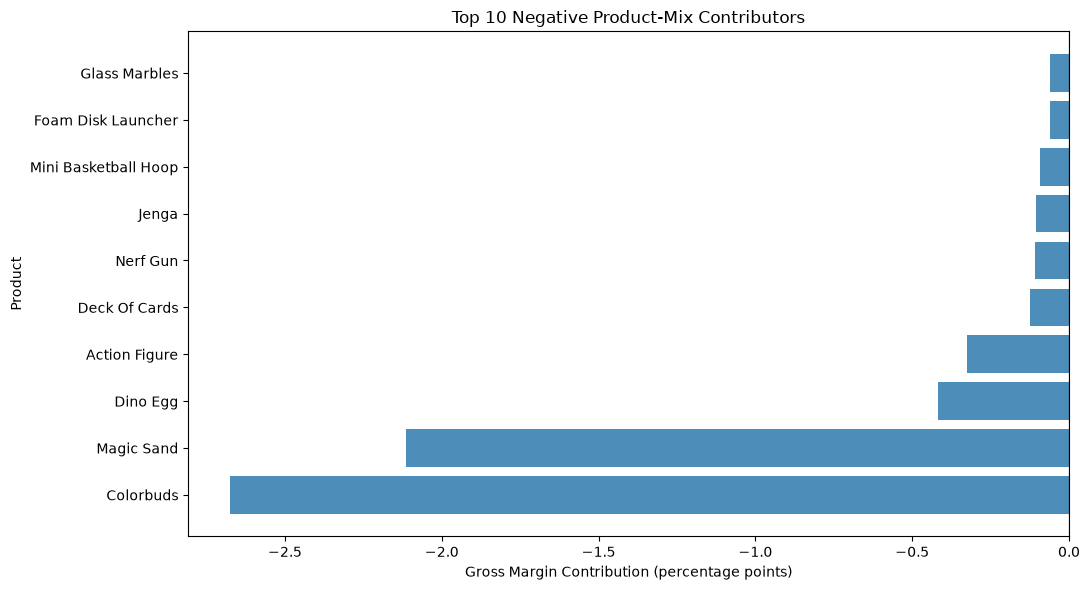

In [30]:
# ==========================================
# ANALYSIS 4D — VISUALIZATIONS
# ==========================================

top_negative_products = (
    product_mix
    .nsmallest(10, 'Margin_Contribution_pp')
    .sort_values('Margin_Contribution_pp')
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_negative_products['Product_Name'],
    top_negative_products['Margin_Contribution_pp'],
    color='#4D8DBA'
)

plt.xlabel('Gross Margin Contribution (percentage points)')
plt.ylabel('Product')
plt.title('Top 10 Negative Product-Mix Contributors')

plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

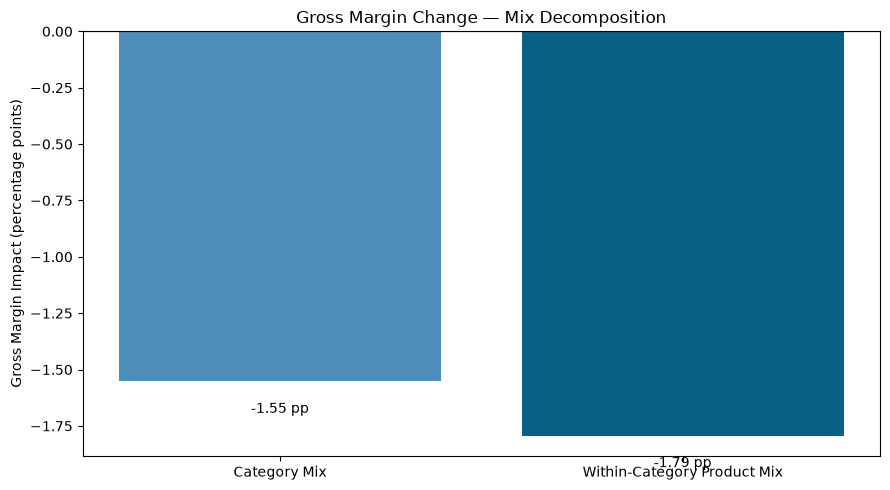

In [31]:
# CHART 2 — Margin Decomposition

effect_names = [
    'Category Mix',
    'Within-Category Product Mix'
]

effect_values = [
    category_mix_total,
    within_category_total
]

plt.figure(figsize=(9, 5))

plt.bar(
    effect_names,
    effect_values,
    color=['#4D8DBA', '#086288']
)

plt.axhline(0, color='black', linewidth=0.8)

plt.ylabel('Gross Margin Impact (percentage points)')
plt.title('Gross Margin Change — Mix Decomposition')

for i, value in enumerate(effect_values):
    plt.annotate(
        f'{value:+.2f} pp',
        (i, value),
        xytext=(0, -15 if value < 0 else 5),
        textcoords='offset points',
        ha='center',
        va='top' if value < 0 else 'bottom'
    )

plt.tight_layout()
plt.show()

In [32]:
# FINAL ANALYSIS 4 VALIDATION

print("========== MARGIN RECONCILIATION ==========")

print(f"Actual Margin Change: {margin_change_pp:.4f} pp")

print(
    f"Product Mix Contribution: "
    f"{total_product_contribution:.4f} pp"
)

print(
    f"Category Mix Contribution: "
    f"{category_mix_total:.4f} pp"
)

print(
    f"Within-Category Mix Contribution: "
    f"{within_category_total:.4f} pp"
)

print(
    f"Category + Within-Category: "
    f"{explained_change:.4f} pp"
)

print(
    "Product reconciliation passed:",
    np.isclose(
        margin_change_pp,
        total_product_contribution,
        atol=0.000001
    )
)

print(
    "Category reconciliation passed:",
    np.isclose(
        margin_change_pp,
        explained_change,
        atol=0.000001
    )
)

========== MARGIN RECONCILIATION ==========
Actual Margin Change: -3.3464 pp
Product Mix Contribution: -3.3464 pp
Category Mix Contribution: -1.5529 pp
Within-Category Mix Contribution: -1.7934 pp
Category + Within-Category: -3.3464 pp
Product reconciliation passed: True
Category reconciliation passed: True
